# Creating group-level models of perceived attributes

In this notebook, we will go through a simple example of creating a group-level generative model of a perceived attribute. Given a set of stimuli and their averaged ratings, we will fit a linear model to the data and use it to edit a GAN-based model to synthesize new stimuli with the modeled attribute. In this case, our generating model will be the official StyleGAN2 (SG2) model trained on the FFHQ dataset.

The ratings used in this notebook are for demonstration purposes and do not come from human judgments. We generated 1000 random faces using SG2 and had the InsightFace model predict its age in years.

## Setup/Preamble

You will need an NVIDIA GPU in order to run this notebook, along with an installation of [Docker](https://docs.docker.com/engine/install/). 

From this directory, run the following commands to build and run the Docker container:

```
docker build -t attribute-demo .
docker run --gpus all -p 8888:8888 -v "${PWD}:/work" attribute-demo
```

The first command builds the Docker image and names it "attribute-demo", while the second command runs the container (mounting your current directory as `/work` in the container) and makes the notebook available at http://127.0.0.1:8888. (After running this command, your terminal may point you to some other randomly generated URL, like http://e1dce6f67787:8888/ but that never worked for me, so I just use http://127.0.0.1:8888).

Once you have run these commands, you can open the notebook by navigating to the aforementioned URL, http://127.0.0.1:8888, in your web browser.

The Docker image downloads NVIDIA's official StyleGAN2 FFHQ weights. Those weights are not in this repo. NVIDIA's license is [here](https://github.com/NVlabs/stylegan2-ada-pytorch/blob/main/LICENSE.txt).

The image also installs InsightFace and downloads its `buffalo_l` model pack, which includes the age network used to generate our age ratings. Those weights are licensed for non-commercial research: https://github.com/deepinsight/insightface

If the StyleGAN weights are missing, the next code cell prints the URL where you can download it (https://api.ngc.nvidia.com/v2/models/nvidia/research/stylegan2/versions/1/files/stylegan2-ffhq-1024x1024.pkl) and stops.

### Formatting the data

This notebook makes use of demo ratings data contained within `demo_attribute_means.csv` and demo latents contained within `demo_latents.npz`. When you are ready to use your own data, replace those two files with your own ratings and stimulus latents, respectively, then run this notebook.

The demo ratings CSV has a `stimulus` column (denoting the stimulus index) plus one column per attribute. Values in an attribute column are meant to represent the average rating obtained from several raters. In this case, we just have one attribute: `age`.

The demo latents file, `demo_latents.npz`, stores two arrays: `stimulus` and `latent`. `stimulus` represents the stimulus index, while each cell of `latent` is one 512-dimensional vector (i.e., a list of 512 numbers, represented as a numpy array) from the StyleGAN2 mapping network at `truncation_psi=0.7`. We will join the two files (the ratings and the latents) on the `stimulus` column. SG2 generally expects an 18 x 512 array of weights, so we repeat the same 512-D vector 18 times to match its expected input format.

### Imports

Below, we will first import the necessary libraries. You will always need to run this cell. Note that the first line "resets" the state of the notebook, so it is not contaminated by earlier runs.

In [12]:
%reset -f
%matplotlib inline

import os
import sys
from dataclasses import dataclass
from typing import Dict, List, Protocol, Sequence, Tuple, TypedDict

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from ipywidgets import IntSlider
from sklearn.linear_model import RidgeCV

### Classes

Next, let's define some helpful types used throughout the notebook. (You can skip reading more about this if you aren't interested in the nitty gritty programming details.)

Our `Config` will hold the paths and seeds, while `Workspace` is that config plus a loaded SG2 generator. Functions that talk to StyleGAN2 directly will take a `Workspace` object to provide the necessary context.

In [13]:
class RatingStats(TypedDict):
    """The stats for one (perceived) attribute column."""

    mean: float
    sd: float
    z: np.ndarray


class Factor(TypedDict):
    """A fitted ridge regression model and its direction in the latent space."""

    model: RidgeCV
    direction: np.ndarray

Ratings = Dict[str, RatingStats] # a mapping of attributes and their statistics
Models = Dict[str, Factor] # a mapping of models and their factors


class StyleGAN(Protocol):
    """The calls to SG2 that this notebook makes."""

    z_dim: int
    c_dim: int
    w_dim: int
    num_ws: int

    def mapping(
        self, z: torch.Tensor, c: torch.Tensor, truncation_psi: float = 1
    ) -> torch.Tensor:
        ...

    def synthesis(self, ws: torch.Tensor, noise_mode: str = "const") -> torch.Tensor:
        ...


@dataclass(frozen=True)
class Config:
    """Configuration for the notebook as a whole.
    Needs to be set before your generator can be loaded."""

    repo: str
    weights: str
    weights_url: str
    ratings_csv: str
    latents_npz: str
    truncation: float
    seed: int
    face_seed: int
    n_faces: int
    image_size: int
    det_size: int
    batch_size: int
    save_images: bool


@dataclass(frozen=True)
class Workspace:
    """The config, device, and generator accessible in one object for
    the sake of convenience.
    """

    config: Config
    device: torch.device
    generator: StyleGAN

### Constants

Next, we will define the constants used in the notebook. This involves creating an instance of the `Config` class with all the information we will need.

When you are ready to use your own data and stimuli, you will need to replace `ratings_csv` and `latents_npz` with your own files.

In [14]:
config = Config(
    repo=os.environ.get("SG2_REPO", "/opt/stylegan2-ada-pytorch"),
    weights=os.environ.get("SG2_PKL", "/opt/stylegan2-ffhq-1024x1024.pkl"),
    weights_url="https://api.ngc.nvidia.com/v2/models/nvidia/research/stylegan2/versions/1/files/stylegan2-ffhq-1024x1024.pkl",
    ratings_csv="demo_attribute_means.csv", # <- when you are ready to use your own data, change this
    latents_npz="demo_latents.npz", # <- this one as well
    truncation=0.7,
    seed=0,
    face_seed=3,
    n_faces=1000,
    image_size=1024, # can make this smaller to run faster (e.g., 256)
    det_size=512, # detector input size; 512 is a good default if working with 1024x1024 images
    batch_size=16, # the number of images to process at once
    save_images=False, # whether to save the images out directly
)

### Functions

Now we define the functions we will use to do all the heavy lifting. Once this cell has been run, each subsequent step below is a call to one or more of these functions, making it easier to understand what is going on. This cell is the most engineering-intensive step; you need not change anything here for now.


In [15]:
def load_generator(config: Config) -> Workspace:
    """Load the StyleGAN2 generator trained on FFHQ.

    Returns a Workspace holding the torch device, the generator, and the
    config. Raises an error if the weights file is missing or if no GPU
    is available to work with.
    """
    if not os.path.isfile(config.weights):
        raise FileNotFoundError(
            f"StyleGAN2 weights not found at {config.weights}. First, download NVIDIA's FFHQ pickle from:\n{config.weights_url}"
        )
        
    sys.path.insert(0, config.repo)
    import dnnlib
    import legacy

    if not torch.cuda.is_available():
        raise RuntimeError("This notebook needs an NVIDIA GPU visible to PyTorch.")

    device: torch.device = torch.device("cuda")
    with dnnlib.util.open_url(config.weights) as handle:
        generator: StyleGAN = legacy.load_network_pkl(handle)["G_ema"].to(device).eval()
        
    return Workspace(config=config, device=device, generator=generator)


def load_age_judge(workspace: Workspace):
    """Load InsightFace's detector and age network.

    Uses the GPU when ONNX Runtime's CUDA provider loads, and the CPU otherwise.
    Detection uses config.det_size. The age crop is taken from the rendered image.
    """
    from insightface.app import FaceAnalysis

    app = FaceAnalysis(
        allowed_modules=["detection", "genderage"],
        providers=["CUDAExecutionProvider", "CPUExecutionProvider"],
    )
    side = workspace.config.det_size
    app.prepare(ctx_id=0, det_size=(side, side))
    provider = app.models["detection"].session.get_providers()[0]
    print(f"InsightFace is using {provider}")
    return app


def judge_ages(app, images: np.ndarray) -> np.ndarray:
    """Return InsightFace's predicted age in years for each RGB image."""
    ages = np.empty(len(images), dtype=np.float64)
    for i, image in enumerate(images):
        pixels = np.ascontiguousarray((np.clip(image, 0.0, 1.0) * 255).astype(np.uint8))
        faces = app.get(pixels[:, :, ::-1])
        if not faces:
            raise RuntimeError(f"InsightFace found no face in image {i}.")
        face = max(faces, key=lambda item: (item.bbox[2] - item.bbox[0]) * (item.bbox[3] - item.bbox[1]))
        ages[i] = float(face.age)
    return ages


def write_demo_data(workspace: Workspace) -> None:
    """Render random faces and store InsightFace's age for each one.

    Make sure to set your config's save_images=True to also write demo_faces/<stimulus>.jpg.
    """
    torch.manual_seed(workspace.config.seed)
    z = torch.randn(workspace.config.n_faces, workspace.generator.z_dim, device=workspace.device)
    c = torch.empty(workspace.config.n_faces, workspace.generator.c_dim, device=workspace.device)
    with torch.no_grad():
        w_layers: torch.Tensor = workspace.generator.mapping(z, c, truncation_psi=workspace.config.truncation)
    latent: np.ndarray = w_layers[:, 0].detach().cpu().numpy().astype(np.float64)

    judge = load_age_judge(workspace)
    ages = np.empty(workspace.config.n_faces, dtype=np.float64)
    batch = workspace.config.batch_size
    image_dir = "demo_faces"
    if workspace.config.save_images:
        os.makedirs(image_dir, exist_ok=True)
    for start in range(0, len(latent), batch):
        images = render_image(workspace, latent[start:start + batch])
        ages[start:start + len(images)] = judge_ages(judge, images)
        if workspace.config.save_images:
            for offset, image in enumerate(images):
                plt.imsave(os.path.join(image_dir, f"{start + offset + 1}.jpg"), np.clip(image, 0.0, 1.0))

    stimulus: np.ndarray = np.arange(1, workspace.config.n_faces + 1)
    pd.DataFrame({"stimulus": stimulus, "age": ages}).to_csv(workspace.config.ratings_csv, index=False)
    np.savez(
        workspace.config.latents_npz,
        stimulus=stimulus,
        latent=latent.astype(np.float32),
    )
    print(
        f"Wrote {workspace.config.n_faces} faces. InsightFace age mean {ages.mean():.1f}, sd {ages.std():.1f}, range {ages.min():.0f} to {ages.max():.0f}."
    )
    if workspace.config.save_images:
        print(f"Wrote {workspace.config.n_faces} images to {image_dir}.")


def load_ratings(workspace: Workspace) -> Tuple[np.ndarray, Ratings, List[str], np.lib.npyio.NpzFile]:
    """Join the ratings CSV to the latents file on stimulus.

    Returns the latent matrix, z-scored ratings, attribute names, and the
    opened latents file. Each rating column is z-scored with its population
    standard deviation.
    """
    means: pd.DataFrame = pd.read_csv(workspace.config.ratings_csv)
    latents: np.lib.npyio.NpzFile = np.load(workspace.config.latents_npz)
    if "stimulus" not in means.columns:
        raise ValueError("The ratings CSV needs a stimulus column!")
    if means["stimulus"].duplicated().any():
        raise ValueError("Stimulus ids must be unique!")

    index = {int(s): i for i, s in enumerate(latents["stimulus"])}
    missing: List[int] = [int(s) for s in means["stimulus"] if int(s) not in index]
    if missing:
        raise ValueError(f"No latent for stimulus ids: {missing[:5]}... (and {len(missing) - 5} more)")

    W: np.ndarray = np.stack(
        [latents["latent"][index[int(s)]] for s in means["stimulus"]]
    ).astype(np.float64)
    if W.ndim != 2 or W.shape[1] != workspace.generator.w_dim:
        raise ValueError(f"latent must be (n, {workspace.generator.w_dim}) mapped latents, got {W.shape}.")

    attributes: List[str] = [column for column in means.columns if column != "stimulus"]
    if not attributes:
        raise ValueError("The CSV has no attribute columns.")

    ratings: Ratings = {}
    for name in attributes:
        raw = means[name].to_numpy(dtype=np.float64)
        sd = raw.std()
        if sd == 0:
            raise ValueError(f"{name} has zero variance.")
        ratings[name] = {
            "mean": float(raw.mean()),
            "sd": float(sd),
            "z": (raw - raw.mean()) / sd
        }
    return W, ratings, attributes, latents


def predict_z(models: Models, name: str, w: np.ndarray) -> float:
    """Return the model's predicted z-score for one latent."""
    w = np.asarray(w, dtype=np.float64).reshape(1, -1)
    return float(models[name]["model"].predict(w)[0])


def edit(models: Models, name: str, w: np.ndarray, z: float) -> np.ndarray:
    """Move a latent, w, so the model would rate the resultant stimulus 
    along that attribute at the given z-score."""
    w = np.asarray(w, dtype=np.float64).reshape(-1)
    return w + (z - predict_z(models, name, w)) * models[name]["direction"]


def fit_models(W: np.ndarray, ratings: Ratings) -> Models:
    """Fit a ridge regression model for each attribute for which you have data.

    `W` represents the latents of the stimuli in the dataset, 
    while `ratings` is a dictionary of attribute names and their mean ratings.
    
    Some other notes:
    - The penalty value is the grid point with the best leave-one-out prediction.
    - R^2 represents fit for leave-one-out cross-validation.
    - The stored direction in the latent space is scaled so that 
      adding it to a given latent raises the predicted
      z-score by 1. The code will raise an error if that check fails.
    """
    models: Models = {}
    alphas = np.logspace(-2, 6, 20)
    for name in ratings:
        model: RidgeCV = RidgeCV(alphas=alphas, scoring="r2").fit(W, ratings[name]["z"])
        coef: np.ndarray = np.ravel(model.coef_).astype(np.float64)        
        direction: np.ndarray = coef / np.dot(coef, coef) # for normalization purposes
        models[name] = {"model": model, "direction": direction}
        print(f"{name}: ridge penalty {model.alpha_:g}, leave-one-out R^2 {model.best_score_:.3f}")
        
    # Check that a step of +1 in the latent space changes the predicted z-score 
    # by the expected amount
    probe: np.ndarray = W[0]
    for name in models:
        step: float = predict_z(models, name, probe + models[name]["direction"]) - predict_z(models, name, probe)
        if abs(step - 1.0) > 1e-4:
            raise AssertionError(f"{name}: a step of +1 changed the prediction by {step}")
    
    print("Sanity check passed: a step of +1 changes the predicted z-score by 1.")
    return models


def sample_latent(workspace: Workspace, seed: int) -> np.ndarray:
    """Sample one new 512-D latent from the generator's mapping network.
    That is, generate a new representation of an image.
    """
    torch.manual_seed(seed)
    z_new = torch.randn(1, workspace.generator.z_dim, device=workspace.device)
    c_new = torch.empty(1, workspace.generator.c_dim, device=workspace.device)
    with torch.no_grad():
        return workspace.generator.mapping(z_new, c_new, truncation_psi=workspace.config.truncation)[0, 0].detach().cpu().numpy()


def render_image(workspace: Workspace, lat: np.ndarray) -> np.ndarray:
    """Render one or more 512-D latents as RGB images at config.image_size, on a 0-1 scale."""
    lat: np.ndarray = np.asarray(lat, dtype=np.float32)
    if lat.ndim == 1:
        lat = lat[None, :]
    ws = torch.tensor(lat, device=workspace.device).unsqueeze(1).repeat(1, workspace.generator.num_ws, 1)
    with torch.no_grad():
        image = workspace.generator.synthesis(ws, noise_mode="const")
    image = (image.clamp(-1, 1) + 1) / 2
    side = workspace.config.image_size
    if image.shape[-2] != side or image.shape[-1] != side:
        image = torch.nn.functional.interpolate(image, size=side, mode="area")
    
    # Change the dimensions to (batch_size, height, width, channels)
    return image.permute(0, 2, 3, 1).detach().cpu().numpy()


def show_demo_face(workspace: Workspace, stimulus: int) -> plt.Figure:
    """Draw one generated demo face and the age InsightFace assigned it."""
    table: pd.DataFrame = pd.read_csv(workspace.config.ratings_csv)
    latents = np.load(workspace.config.latents_npz)
    match = table.loc[table["stimulus"] == stimulus]
    if match.empty:
        raise ValueError(f"No stimulus {stimulus} in the ratings file.")
        
    index = {int(item): i for i, item in enumerate(latents["stimulus"])}
    image = render_image(workspace, np.asarray(latents["latent"][index[int(stimulus)]]))[0]
    age = float(match["age"].iloc[0])
    
    fig = plt.figure(figsize=(3, 3))
    plt.imshow(image)
    plt.axis("off")
    plt.title(f"stimulus {int(stimulus)}\n{round(age)} years")
    
    return fig

def show_ratings(
    workspace: Workspace, w: np.ndarray, models: Models, ratings: Ratings, attributes: Sequence[str]
) -> None:
    """Show a face and print the model's rating for each attribute."""
    
    plt.figure(figsize=(3, 3))
    plt.imshow(render_image(workspace, w)[0])
    plt.axis("off")
    plt.show()
    
    for name in attributes:
        z_hat = predict_z(models, name, w)
        raw_hat = z_hat * ratings[name]["sd"] + ratings[name]["mean"]
        print(f"{name}: predicted z-score = {z_hat:+.2f}; predicted rating = {raw_hat:.1f}")


def show_attribute_faces(
    workspace: Workspace,
    w: np.ndarray,
    models: Models,
    ratings: Ratings,
    attributes: Sequence[str],
    levels: Sequence[float] = (-3, -1.5, 0, 1.5, 3),
) -> None:
    """Show the face edited to each rating z-score along every attribute.

    Above the panel we display the predicted z-score and 'raw' prediction in the original
    attribute scale (in this case, years).
    The default endpoints are +/-3 standard deviations of the rating scale.
    """
    
    fig, axes = plt.subplots(
        len(attributes),
        len(levels),
        figsize=(2.2 * len(levels), 2.6 * len(attributes)),
    )
    if len(attributes) == 1:
        axes = np.array([axes])

    for row, name in enumerate(attributes):
        edited = [edit(models, name, w, level) for level in levels]
        images = render_image(workspace, np.stack(edited))
        
        for col, (level, image) in enumerate(zip(levels, images)):
            got = predict_z(models, name, edited[col])
            if abs(got - level) > 1e-4:
                raise AssertionError(f"{name} at {level} predicted {got}")
                
            raw = got * ratings[name]["sd"] + ratings[name]["mean"]
            ax = axes[row, col]
            ax.imshow(image)
            ax.set_title(f"z = {got:+.2f}\n{raw:.0f} years", fontsize=9)
            ax.axis("off")

    plt.tight_layout()
    plt.show()

### Load StyleGAN2

`load_generator` takes `config` and returns a `Workspace`, defining the generator network, the device (aka, your NVIDIA GPU), and the config itself wrapped into the workspace.

In [16]:
workspace: Workspace = load_generator(config)

## Main tutorial

Finally, our setup is complete! We can now get to the fun part.

### Step 0: Generate the demo data

These cells render the demo faces and their ages. The data are included here, so you shouldn't need to run the `write_demo_data()` function. If you have your own ratings CSV and latents file, point `config.ratings_csv` and `config.latents_npz` at those files instead.

We generate 1000 faces here, where each face is a random sample from SG2's latent space. We use InsightFace to predict the age of each face to get the ratings for this demo.

In [17]:
# write_demo_data(workspace) # You can skip this if you already have the ratings CSV and latent files for the demo
ratings_data = pd.read_csv(workspace.config.ratings_csv)
ratings_data.head()

,stimulus,age
0,1,36.0
1,2,39.0
2,3,5.0
3,4,68.0
4,5,25.0


#### Browse the demo faces

If you'd like to see what the faces look like, run the below cell and move the slider to look at the generated faces one at a time, along with the age rating provided by InsightFace.

(Forgive the rigmarole way of displaying the images; for some reason I couldn't get interactive sliders provided by `ipywidget` to work with this version of Python/Jupyter notebook, so we are stuck with this for now.)

IntSlider(value=1, description='stimulus', max=1000, min=1)

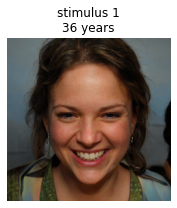

In [18]:
from IPython.display import display, update_display

stimuli = pd.read_csv(workspace.config.ratings_csv)["stimulus"].astype(int)
stimulus_slider = IntSlider(
    min=int(stimuli.min()),
    max=int(stimuli.max()),
    step=1,
    value=int(stimuli.min()),
    description="stimulus",
)

face_view = {}

def show_selected(_change=None):
    fig = show_demo_face(workspace, int(stimulus_slider.value))
    if "id" not in face_view:
        face_view["id"] = display(fig, display_id=True).display_id
    else:
        update_display(fig, display_id=face_view["id"])
    plt.close(fig)

stimulus_slider.observe(show_selected, names="value")
display(stimulus_slider)
show_selected()

### Step 1: Load the ratings

Given your `workspace` above, get the stimuli and their ratings.

In [19]:
W: np.ndarray # the numpy array of the stimulus representations in the latent space
ratings: Ratings # 
attributes: List[str] # the list of attributes you have ratings for
latents: np.lib.npyio.NpzFile # like a dictionary with "stimulus" and "latent" entries
    
W, ratings, attributes, latents = load_ratings(workspace)

### Step 2: Fit your model(s)

We can call `fit_models` to run ridge regression on each of the attributes for which you have ratings. We first normalize the rating data to get z-scores (mean=0, population_sd=1) before fitting. The penalty term, alpha, is chosen via search from a log grid by leave-one-out prediction; a larger penalty term leads to smaller coefficients. The number printed with the penalty is the leave-one-out R^2.

The `direction` is the coefficient vector scaled so that adding that vector directly to an image's latent raises that image's predicted z-score by 1.

In [20]:
models: Models = fit_models(W, ratings)

age: ridge penalty 23.3572, leave-one-out R^2 0.659
Sanity check passed: a step of +1 changes the predicted z-score by 1.


### Step 3: Predict ratings of stimuli using the model

Let's see what our model thinks of a new face that was not in the original sample it was trained on. The z-score is the model's rating. We can also put that z-score back into the "original" scale of the dataset (so here we will see an age in years).

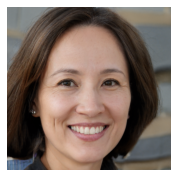

age: predicted z-score = +0.49; predicted rating = 48.9


In [21]:
new_face_w: np.ndarray = sample_latent(workspace, workspace.config.face_seed)
show_ratings(workspace, new_face_w, models, ratings, attributes)

### Step 4: Transform images using the model

Below you can run the cell to create a results "reel", showing what a given identity looks like at different levels of the perceived attribute. Each image in the reel shows the predicted z-score and corresponding rating (i.e., age in years). Of course, there is no ground truth here, and the exact numbers that the model predicts can be inaccurate. However, notice that even if the predictions are inaccurate, the face does get older as we move from left to right along the reel. Consequently, transformation tends to work better than prediction.

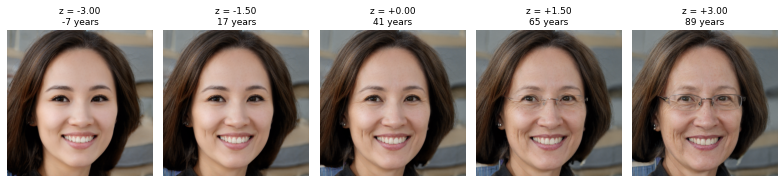

In [22]:
show_attribute_faces(workspace, new_face_w, models, ratings, attributes)

# Contact

If you would like to learn more about this work or use some of our existing models, please reach out to me at stefanu@illinois.edu.